In [9]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"
import pandas as pd
from datetime import datetime
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
from utils.selection import *

import seaborn as sns

# Project data path
DATA_PATH='/home/bule/berner_daten_analyse/data'

In [38]:
df

,p_id,age,sex,nihss,selbststaendig,prehypert,systol,toast,mrs,MED_prestatin,MED_Parenteral,MED_Dabigatran_Pradaxa,MED_Rivaroxaban_Xarelto,MED_Vit_K_ag,MED_Ticagrelor,MED_Clopidogrel,mrs_unfavorable,p_idx
0,76813.0,27.900000,0,8,1,0,43,3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
1,442968.0,94.100000,1,4,0,0,72,1,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,1
2,481858.0,89.000000,1,23,1,1,87,1,5.0,0.0,0.0,0.0,0.0,0.0,0.1,0.0,1,2
3,653853.0,55.400000,1,5,1,0,10,2,6.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1,3
4,768081.0,69.649315,1,16,1,1,87,1,1.0,0.0,0.0,0.0,0.0,0.0,0.1,0.0,0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
292,14150158.0,81.100000,1,11,1,1,60,4,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1,292
293,14239248.0,81.100000,1,13,1,0,71,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,293
294,82298262.0,62.400000,0,2,1,0,59,4,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,294
295,82364672.0,81.300000,0,13,1,1,38,1,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1,295


In [5]:
df=pd.read_csv(os.path.join(DATA_PATH,'clinical','baseline_bern_test_impute_10n.csv'))
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   p_id                     297 non-null    float64
 1   age                      297 non-null    float64
 2   sex                      297 non-null    int64  
 3   nihss                    297 non-null    int64  
 4   selbststaendig           297 non-null    int64  
 5   prehypert                297 non-null    int64  
 6   systol                   297 non-null    int64  
 7   toast                    297 non-null    int64  
 8   mrs                      297 non-null    float64
 9   MED_prestatin            297 non-null    float64
 10  MED_Parenteral           297 non-null    float64
 11  MED_Dabigatran_Pradaxa   297 non-null    float64
 12  MED_Rivaroxaban_Xarelto  297 non-null    float64
 13  MED_Vit_K_ag             297 non-null    float64
 14  MED_Ticagrelor           2

## AGE

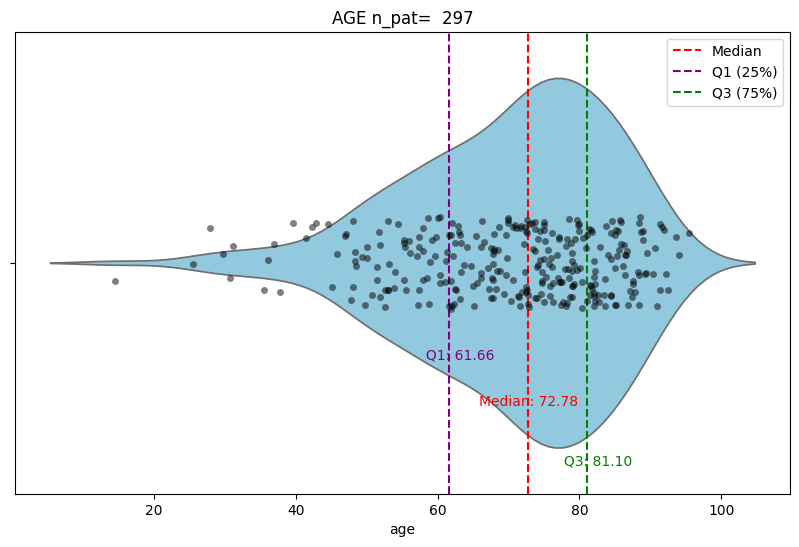

In [ ]:
median_age = df['age'].median()
q1_age = df['age'].quantile(0.25)
q3_age = df['age'].quantile(0.75)

plt.figure(figsize=(10, 6))
sns.violinplot(data=df, x='age', inner=None, color="skyblue")
sns.stripplot(data=df, x='age', jitter=True, alpha=0.5, color="black")

plt.axvline(median_age, color='red', linestyle='--', label='Median')
plt.axvline(q1_age, color='purple', linestyle='--', label='Q1 (25%)')
plt.axvline(q3_age, color='green', linestyle='--', label='Q3 (75%)')
plt.text(median_age, 0.3, f'Median: {median_age:.2f}', color='red', va='center', ha='center')
plt.text(q1_age, 0.2, f'     Q1: {q1_age:.2f}', color='purple', va='center', ha='center')
plt.text(q3_age, 0.43, f'     Q3: {q3_age:.2f}', color='green', va='center', ha='center')
plt.title(f'AGE n_pat=  {len(df)}')
plt.legend()
plt.show()


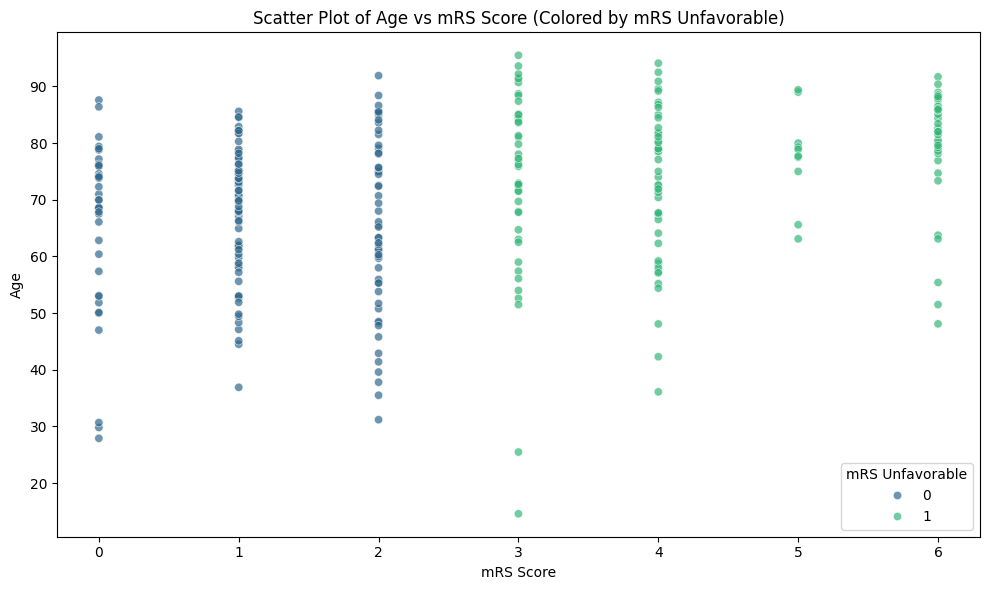

In [ ]:
plt.figure(figsize=(10, 6))
scatter = sns.scatterplot(data=df, x='mrs', y='age', hue='mrs_unfavorable', palette='viridis', alpha=0.7)

plt.title('Scatter Plot of Age vs mRS Score (Colored by mRS Unfavorable)')
plt.ylabel('Age')
plt.xlabel('mRS Score')

plt.legend(title='mRS Unfavorable', loc='lower right', frameon=True)
plt.tight_layout()
plt.show()